# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170277        # <-- your full roll number
NAME = "Kushagra Rai"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170277   Name: Kushagra Rai   Fingerprint: 0C1C3332   Tickets: 14

Ticket_ID                                                                                  Ticket_Text
      T01                                                    The printer won't print; it isn't jammed.
      T02                                                 See https://lms.thapar.edu/help for details.
      T03                                                  The state-of-the-art lab (Lab-3) is closed.
      T04                         LMS is showing an error after restarting the system. This is urgent.
      T05      I can't open the password before the assignment deadline. It works on another computer.
      T06       I was locked out of the projector after the latest update. I have tried several times!
      T07          Student portal keeps asking for login while uploading the file. Can you check this?
      T08     I tried restarting the student portal before the assignment deadline. Please r

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Your code

# Q1: Preprocessing pipeline

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []
for i, result in enumerate(processed):
    rows.append({
        "Ticket_ID": df.iloc[i]["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)

# Add total row
total = {"Ticket_ID": "TOTAL"}
for col in ["Sentences", "Tokens", "Punctuation Tokens",
            "Stopwords", "Final Tokens"]:
    total[col] = summary[col].sum()

# Unique tokens are counted separately for each ticket in the table
total["Unique Tokens"] = summary["Unique Tokens"].sum()

summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)
display(summary)

# Show token details for the first ticket
i = 0
print("Selected ticket:", df.iloc[i]["Ticket_ID"])
print("Text:", df.iloc[i]["Ticket_Text"])
print("\nSentences:", processed[i]["sentences"])
print("\nActual tokens:", processed[i]["tokens"])
print("\nPunctuation tokens:", processed[i]["punct"])
print("\nStopwords:", processed[i]["stops"])
print("\nFinal tokens:", processed[i]["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,11,2,3,10,6
1,T02,1,7,2,1,7,4
2,T03,1,9,3,2,9,4
3,T04,2,14,2,6,12,6
4,T05,2,17,2,6,15,9
5,T06,2,18,2,9,16,7
6,T07,2,16,2,6,16,8
7,T08,2,15,2,5,13,8
8,T09,2,16,2,4,15,10
9,T10,1,10,1,3,10,6


Selected ticket: T01
Text: The printer won't print; it isn't jammed.

Sentences: ["The printer won't print; it isn't jammed."]

Actual tokens: ['the', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']

Punctuation tokens: [';', '.']

Stopwords: ['the', 'it', 'is']

Final tokens: ['printer', 'wo', "n't", 'print', "n't", 'jammed']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* These tokens come from contractions that word_tokenize() splits into separate tokens. Since the preprocessing pipeline removes punctuation tokens and stopwords individually, contraction fragments may remain in the final token list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

# Combine all raw tickets and the provided test lines
all_texts = df["Ticket_Text"].tolist()

# 1. Extract words longer than 5 letters
long_words = [re.findall(r"\b[A-Za-z]{6,}\b", text)
              for text in all_texts]

# 2. Extract numbers, preserving decimals and versions
number_pattern = r"\b\d+(?:\.\d+)*%?\b"
numbers = [re.findall(number_pattern, text) for text in all_texts]

# 3. Extract capitalized words
capitalized_words = [re.findall(r"\b[A-Z][a-zA-Z]*\b", text)
                     for text in all_texts]

# 4. Extract words beginning with a vowel
vowel_words = [re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text)
               for text in all_texts]

print("LONG WORDS:")
for i, words in enumerate(long_words):
    print(df.iloc[i]["Ticket_ID"], words)

print("\nNUMBERS:")
for i, nums in enumerate(numbers):
    print(df.iloc[i]["Ticket_ID"], nums)

print("\nCAPITALIZED WORDS:")
for i, words in enumerate(capitalized_words):
    print(df.iloc[i]["Ticket_ID"], words)

print("\nWORDS BEGINNING WITH A VOWEL:")
for i, words in enumerate(vowel_words):
    print(df.iloc[i]["Ticket_ID"], words)

# 5. Replace email addresses, URLs and phone numbers
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s]+|www\.[^\s]+"
phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\d{3,5}[- ]?)\d{4,6}(?!\w)"

def redact_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nREPLACEMENT TESTS:")
for line in TEST_LINES:
    print("Original:", line)
    print("Redacted:", redact_text(line))
    print()


LONG WORDS:
T01 ['printer', 'jammed']
T02 ['thapar', 'details']
T03 ['closed']
T04 ['showing', 'restarting', 'system', 'urgent']
T05 ['password', 'before', 'assignment', 'deadline', 'another', 'computer']
T06 ['locked', 'projector', 'latest', 'update', 'several']
T07 ['Student', 'portal', 'asking', 'uploading']
T08 ['restarting', 'student', 'portal', 'before', 'assignment', 'deadline', 'Please', 'resolve']
T09 ['student', 'portal', 'connected', 'campus', 'Please']
T10 []
T11 ['failed', 'problem', 'occurs']
T12 ['Projector', 'asking', 'restarting', 'system', 'problem', 'occurs']
T13 ['unable', 'restarting', 'system', 'problem', 'occurs']
T14 ['Python', 'asking', 'Please']

NUMBERS:
T01 []
T02 []
T03 ['3']
T04 []
T05 []
T06 []
T07 []
T08 []
T09 []
T10 ['2', '30', '3.5']
T11 []
T12 []
T13 []
T14 []

CAPITALIZED WORDS:
T01 ['The']
T02 ['See']
T03 ['The', 'Lab']
T04 ['LMS', 'This']
T05 ['I', 'It']
T06 ['I', 'I']
T07 ['Student', 'Can']
T08 ['I', 'Please']
T09 ['I', 'Wi', 'Fi', 'Please']
T10 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized words are capitalized only because they occur at the beginning of a sentence, such as “The” and “I”. Other words, such as “Python” and “LMS”, are capitalized because they are proper names or acronyms. The exact count depends on the generated tickets and the extraction results.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern that preserves special token types
pattern = (
    r"https?://[^\s<>]+"
    r"|www\.[^\s<>.,;!?]+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+?\d{1,3}[- ]\d{5}[- ]\d{4}"
    r"|\d{4}[- ]\d{3}[- ]\d{4}"
    r"|\d+(?:\.\d+)+%?"
    r"|\d+%?"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+(?:'[A-Za-z]+)?"
    r"|[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Test on the provided TEST_LINES
print("CUSTOM TOKENIZER — TEST LINES")
for line in TEST_LINES:
    print("\nText:", line)
    print("My tokens:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

# Test on generated tickets
print("\n\nCUSTOM TOKENIZER — GENERATED TICKETS")
different_tickets = []

for _, row in df.iterrows():
    custom = my_tokenize(row["Ticket_Text"])
    standard = word_tokenize(row["Ticket_Text"])

    if custom != standard:
        different_tickets.append(row["Ticket_ID"])

    print(f"\n{row['Ticket_ID']}")
    print("Custom:", custom)
    print("Standard:", standard)

print("\nNumber of tickets tokenized differently:",
      len(different_tickets), "out of", len(df))
print("Different ticket IDs:", different_tickets)


CUSTOM TOKENIZER — TEST LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar', '.', 'edu', '/', 'it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokens: ['Call', '+91 98765 4321', '0', ',', '+91-98765-4321', '0', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab i

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 5

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [11]:
# Your code

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"ing$", min=4)
wnl = WordNetLemmatizer()

def wn_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

# Unique final tokens from all tickets
unique_words = sorted(set(
    word for item in processed for word in item["final"]
))

tagged = pos_tag(unique_words)
rows = []

for word, tag in tagged:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp.stem(word)
    lemma = wnl.lemmatize(word, wn_pos(tag))

    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

comparison = pd.DataFrame(rows)
display(comparison)

print("Unique final tokens:", len(unique_words))
print("Words with differing outputs:", len(comparison))
print("Regexp rule: remove the suffix 'ing'")
print("Dataset examples supporting the rule: restarting, uploading")


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,campus,campu,camp,campus,campus
3,closed,close,clos,closed,close
4,computer,comput,comput,computer,computer
5,connected,connect,connect,connected,connect
6,deadline,deadlin,deadlin,deadline,deadline
7,details,detail,detail,details,detail
8,error,error,er,error,error
9,failed,fail,fail,failed,fail


Unique final tokens: 61
Words with differing outputs: 37
Regexp rule: remove the suffix 'ing'
Dataset examples supporting the rule: restarting, uploading


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: Lancaster stemming may reduce a word too aggressively, removing part of its meaningful root and making it less recognizable.

Under-stemming: Words such as “restarting” and “restarted” may not be reduced to the same form by a simple suffix rule that removes only “ing”.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,189,91,0.4815
1,S2,161,84,0.5217
2,S3,94,61,0.6489
3,S4,94,61,0.6489



TOP 10 WORDS — S1
[('.', 22), ('the', 19), ('i', 6), ('after', 5), ("n't", 4), ('is', 4), ('for', 4), ('restarting', 4), ('it', 3), ('system', 3)]

TOP 10 WORDS — S3
[("n't", 4), ('restarting', 4), ('system', 3), ('open', 3), ('student', 3), ('portal', 3), ('keeps', 3), ('asking', 3), ('login', 3), ('please', 3)]


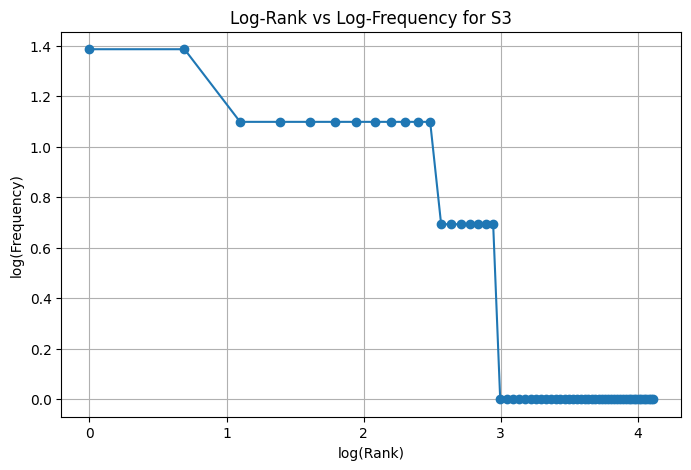


TOP 5 BIGRAMS — S1
[(('.', 'the'), 6), (('.', 'i'), 5), (('restarting', 'the'), 4), (('after', 'restarting'), 3), (('the', 'system'), 3)]

TOP 5 BIGRAMS — S3
[(('restarting', 'system'), 3), (('student', 'portal'), 3), (('keeps', 'asking'), 3), (('asking', 'login'), 3), (('problem', 'occurs'), 3)]


In [12]:
# Your code

from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import ngrams
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

porter = PorterStemmer()

# S1: all tokens
S1 = [token for result in processed for token in result["tokens"]]

# S2: tokens without punctuation
S2 = [token for result in processed for token in result["tokens"]
      if not is_punct(token)]

# S3: final tokens (no punctuation or stopwords)
S3 = [token for result in processed for token in result["final"]]

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]

# Calculate corpus statistics
corpora = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}
stats = []

for name, tokens in corpora.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

print("CORPUS STATISTICS")
display(pd.DataFrame(stats))

# Top 10 words in S1 and S3
print("\nTOP 10 WORDS — S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS — S3")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency) for S3
freq = Counter(S3)
ranked_freq = sorted(freq.values(), reverse=True)

ranks = np.arange(1, len(ranked_freq) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(ranked_freq), marker="o", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log-Rank vs Log-Frequency for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams for S1 and S3
print("\nTOP 5 BIGRAMS — S1")
print(Counter(ngrams(S1, 2)).most_common(5))

print("\nTOP 5 BIGRAMS — S3")
print(Counter(ngrams(S3, 2)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR (Type-Token Ratio) changes from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter stemming combines related word forms into common stems. This reduces the number of unique tokens relative to the total token count in many cases. The exact change depends on the generated dataset.